In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random

## Primal-Dual Sub-gradient Descent

In [2]:
def regret_gradient_descent(T, c1, c2, b1, b2, d):

  '''
  Compute the unmet demand, payment regret, and cost regret
  given a time horizon T, quadratic cost function with coefficients c1 and c2,
  and coefficients b1, b2 for the linear component of the respective cost
  functions. Both the cost functions are drawn from a distribution with
  probability 0.5 each, and demand d for the gradient descent algorithm
  '''

  epsilon = 1/np.sqrt(T) #Initialize step size parameter
  pr_val = 0 #Initialize price
  pr_lb = 0
  pr_ub = 1
  payment_regret = 0
  cost_regret = 0
  unmet_demand_regret = 0
  unmet_demand_relaxed = 0
  opt_price1 = 2*c1*d + b1
  opt_price2 = 2*c2*d + b2

  for t in range(T):
    c = random.uniform(c1, c2) #Pick cost function at random
    demand_pr = pr_val/(2*c) #Compute demand at current price
    unmet_demand_regret += max(d - demand_pr, 0)
    unmet_demand_relaxed += d - demand_pr
    if c == c1:
      payment_regret += pr_val * demand_pr - opt_price1 * d
      cost_regret += c1*((demand_pr)**2) - c1 * (d**2)
    else:
      payment_regret += pr_val * demand_pr - opt_price2 * d
      cost_regret += c2*((demand_pr)**2) - c2 * (d**2)

    pr_val = max(pr_val - epsilon * (demand_pr-d), 0)

  return unmet_demand_regret, cost_regret, payment_regret, unmet_demand_relaxed

In [3]:
#Initialize Problem instance
c1 = 1/6 #coefficient of quadratic cost function
c2 = 1/12 #coefficient of quadratic cost function
b1 = 0 #coefficient of linear part of the cost function
b2 = 1/4 #coefficient of linear part of the cost function
d = 1 #total customer demand
T_range = [100, 200, 300, 400, 500, 750, 1000, 2000, 3000, 4000, 5000, 10000, 20000] #Number of time periods

unmet_demand_regret_arr = []
unmet_demand_relaxed_arr = []
cost_regret_arr = []
payment_regret_arr = []
for T in T_range:
  unmet_demand_regret, cost_regret, payment_regret, unmet_demand_relaxed = regret_gradient_descent(T, c1, c2, b1, b2, d)
  unmet_demand_regret_arr.append(unmet_demand_regret)
  cost_regret_arr.append(cost_regret)
  payment_regret_arr.append(payment_regret)
  unmet_demand_relaxed_arr.append(unmet_demand_relaxed)

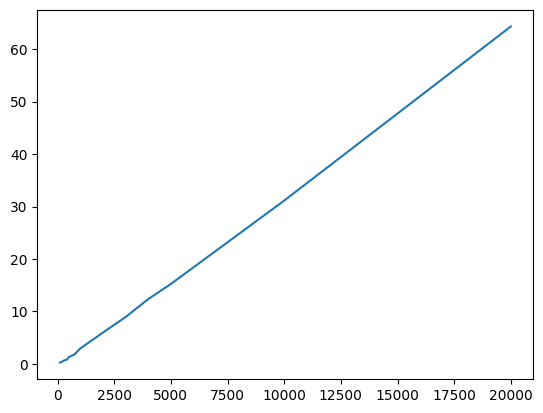

In [4]:
plt.plot(T_range, cost_regret_arr)

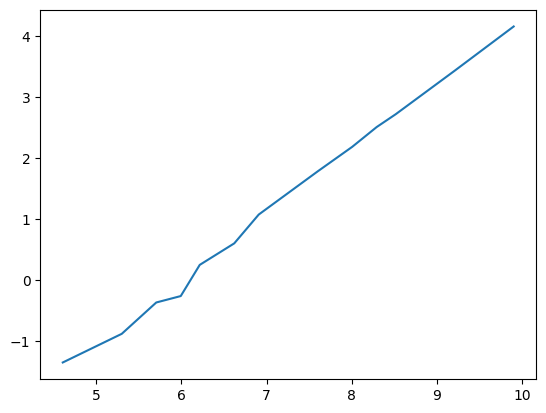

In [5]:
plt.plot(np.log(T_range), np.log(cost_regret_arr))

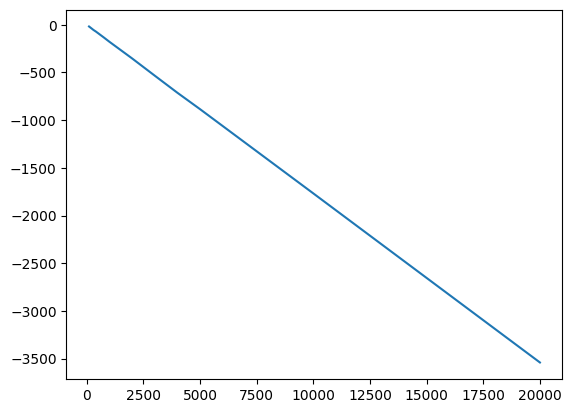

In [6]:
plt.plot(T_range, payment_regret_arr)

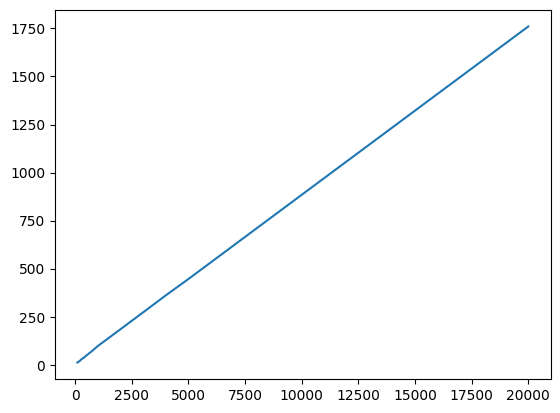

In [7]:
plt.plot(T_range, unmet_demand_regret_arr)